In [2]:
import pandas as pd
import joblib

In [3]:
credit_score = pd.read_csv("./Data/credit_score_imputed.csv")
credit_score_preprocessor = joblib.load("./Data/credit_score_preprocessor.pkl")

Splitting the dataset

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
X = credit_score.drop(columns=['A1'])
y = credit_score['A1'].values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

Model training

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
# from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

In [8]:
y_train_xgb = y_train - 1
y_test_xgb = y_test - 1

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'k-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(kernel='rbf', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    # 'XGBoost': XGBClassifier(n_estimators=100, eval_metric='mlogloss', random_state=42)
}

baseline_results = []
confusion_matrices = {}

In [9]:
for name, model in models.items():
    model_pipeline = Pipeline(steps=[("preprocessor", credit_score_preprocessor), (name, model)])
    
    if name == 'XGBoost':
        model_pipeline.fit(X_train, y_train_xgb)
        preds = model_pipeline.predict(X_test) + 1
    else:
        model_pipeline.fit(X_train, y_train)
        preds = model_pipeline.predict(X_test)
    
    confusion_matrices[name] = confusion_matrix(y_test, preds)
    
    baseline_results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Macro Precision': precision_score(y_test, preds, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, preds, average='macro', zero_division=0),
        'Macro F1-Score': f1_score(y_test, preds, average='macro', zero_division=0),
        'Weighted F1-Score': f1_score(y_test, preds, average='weighted', zero_division=0)
    })

df_baseline = pd.DataFrame(baseline_results)
display(df_baseline.style.background_gradient(cmap='Blues', subset=['Accuracy', 'Macro F1-Score']))

,Algorithm,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,Logistic Regression,0.548128,0.332722,0.312664,0.319111,0.529749
1,k-Nearest Neighbors,0.625668,0.512015,0.430375,0.451181,0.613959
2,Support Vector Machine,0.585561,0.450846,0.289893,0.295618,0.514009
3,Random Forest,0.585561,0.339502,0.278931,0.279906,0.531956


Visualizing the results

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

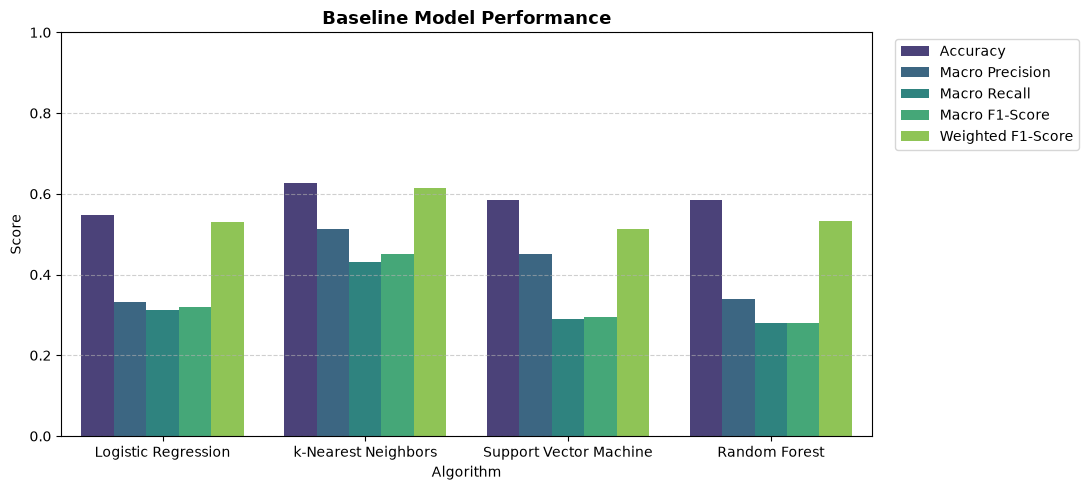

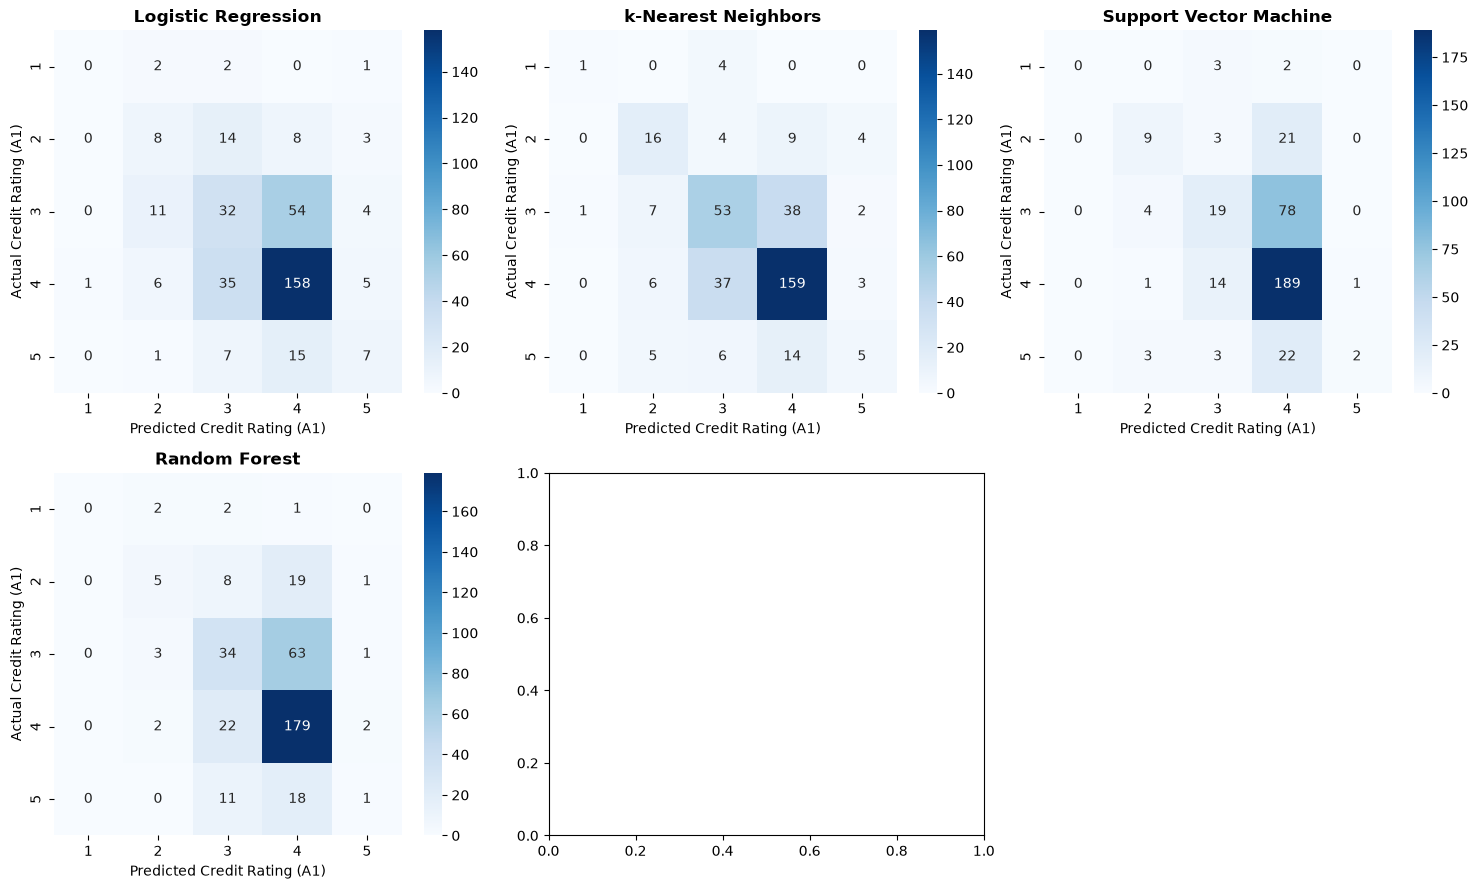

In [11]:
df_plot = df_baseline.melt(id_vars='Algorithm', var_name='Metric', value_name='Score')

plt.figure(figsize=(11, 5))
sns.barplot(data=df_plot, x='Algorithm', y='Score', hue='Metric', palette='viridis')
plt.title('Baseline Model Performance', fontsize=13, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel('Score')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5])
    axes[i].set_title(f'{name}', fontweight='bold')
    axes[i].set_xlabel('Predicted Credit Rating (A1)')
    axes[i].set_ylabel('Actual Credit Rating (A1)')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

Using cross validation

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

cv_summary = []

for name, model in models.items():
    model_pipeline = Pipeline(steps=[("preprocessor", credit_score_preprocessor), (name, model)])
    
    y_cv = (y - 1) if name == 'XGBoost' else y
    
    cv_scores = cross_validate(model_pipeline, X, y_cv, cv=skf, scoring=scoring, n_jobs=-1)
    
    cv_summary.append({
        'Algorithm': name,
        'Mean CV Accuracy': f"{cv_scores['test_accuracy'].mean():.3f} (±{cv_scores['test_accuracy'].std():.3f})",
        'Mean CV Precision': f"{cv_scores['test_precision_macro'].mean():.3f}",
        'Mean CV Recall': f"{cv_scores['test_recall_macro'].mean():.3f}",
        'Mean CV Macro F1': f"{cv_scores['test_f1_macro'].mean():.3f} (±{cv_scores['test_f1_macro'].std():.3f})"
    })

df_cv = pd.DataFrame(cv_summary)
display(df_cv)

,Algorithm,Mean CV Accuracy,Mean CV Precision,Mean CV Recall,Mean CV Macro F1
0,Logistic Regression,0.535 (±0.010),0.375,0.349,0.348 (±0.034)
1,k-Nearest Neighbors,0.621 (±0.020),0.509,0.434,0.457 (±0.059)
2,Support Vector Machine,0.580 (±0.021),0.495,0.305,0.319 (±0.019)
3,Random Forest,0.587 (±0.005),0.465,0.309,0.325 (±0.027)


In [14]:
master_results = []

# Populate baseline results into the master list
for result in baseline_results:
    res_copy = result.copy()
    res_copy['Experimental Setup'] = 'Baseline'
    master_results.append(res_copy)

Hyperparameter tuning

In [15]:
from sklearn.model_selection import GridSearchCV

In [16]:
param_grids = {
    'Logistic Regression': {
        'classifier__C': [0.01, 0.1, 1.0, 10.0],
        'classifier__penalty': ['l1', 'l2'],
        'classifier__solver': ['liblinear', 'saga']
    },
    'k-Nearest Neighbors': {
        'classifier__n_neighbors': [3, 5, 7, 9, 11, 15],
        'classifier__weights': ['uniform', 'distance'],
        'classifier__metric': ['euclidean', 'manhattan']
    },
    'Support Vector Machine': {
        'classifier__C': [0.1, 1.0, 10.0, 100.0],
        'classifier__kernel': ['linear', 'rbf'],
        'classifier__gamma': ['scale', 'auto']
    },
    'Random Forest': {
        'classifier__n_estimators': [50, 100, 200],
        'classifier__max_depth': [None, 8, 12, 16],
        'classifier__min_samples_split': [2, 5, 10],
        'classifier__class_weight': [None, 'balanced']
    }
}

tuned_results = []
best_estimators = {}

for name, model in models.items():
    print(f"Running GridSearchCV for {name}...")
    
    pipeline = Pipeline(steps=[
        ("preprocessor", credit_score_preprocessor),
        ("classifier", model)
    ])
    
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='f1_macro',
        cv=skf,
        n_jobs=-1
    )
    
    grid_search.fit(X_train, y_train)
    best_pipeline = grid_search.best_estimator_
    best_estimators[name] = best_pipeline
    
    preds = best_pipeline.predict(X_test)
    
    print(f"Best Parameters for {name}: {grid_search.best_params_}\n")
    
    result_dict = {
        'Algorithm': name,
        'Experimental Setup': 'Hyperparameter Tuned',
        'Accuracy': accuracy_score(y_test, preds),
        'Macro Precision': precision_score(y_test, preds, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, preds, average='macro', zero_division=0),
        'Macro F1-Score': f1_score(y_test, preds, average='macro', zero_division=0),
        'Weighted F1-Score': f1_score(y_test, preds, average='weighted', zero_division=0)
    }
    
    tuned_results.append(result_dict)
    master_results.append(result_dict)

df_tuned = pd.DataFrame(tuned_results)
print("Hyperparameter Tuning Results")
display(df_tuned.style.background_gradient(cmap='Blues', subset=['Accuracy', 'Macro F1-Score']))

Running GridSearchCV for Logistic Regression...


C:\Users\cesta\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Best Parameters for Logistic Regression: {'classifier__C': 10.0, 'classifier__penalty': 'l1', 'classifier__solver': 'saga'}

Running GridSearchCV for k-Nearest Neighbors...
Best Parameters for k-Nearest Neighbors: {'classifier__metric': 'euclidean', 'classifier__n_neighbors': 3, 'classifier__weights': 'uniform'}

Running GridSearchCV for Support Vector Machine...
Best Parameters for Support Vector Machine: {'classifier__C': 100.0, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Running GridSearchCV for Random Forest...
Best Parameters for Random Forest: {'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}

Hyperparameter Tuning Results


,Algorithm,Experimental Setup,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,Logistic Regression,Hyperparameter Tuned,0.548128,0.329157,0.312664,0.318153,0.531637
1,k-Nearest Neighbors,Hyperparameter Tuned,0.572193,0.422168,0.404981,0.406962,0.575416
2,Support Vector Machine,Hyperparameter Tuned,0.612299,0.628443,0.461923,0.490951,0.610244
3,Random Forest,Hyperparameter Tuned,0.572193,0.349216,0.347683,0.345308,0.552876


Dimensionality reduction

In [21]:
from sklearn.decomposition import PCA

In [18]:
pca_results = []

for name, model in models.items():
    pca_pipeline = Pipeline(steps=[
        ("preprocessor", credit_score_preprocessor),
        ("pca", PCA(n_components=0.90, random_state=42)),
        ("classifier", model)
    ])
    
    pca_pipeline.fit(X_train, y_train)
    preds = pca_pipeline.predict(X_test)
    
    result_dict = {
        'Algorithm': name,
        'Experimental Setup': 'PCA (90% Variance)',
        'Accuracy': accuracy_score(y_test, preds),
        'Macro Precision': precision_score(y_test, preds, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, preds, average='macro', zero_division=0),
        'Macro F1-Score': f1_score(y_test, preds, average='macro', zero_division=0),
        'Weighted F1-Score': f1_score(y_test, preds, average='weighted', zero_division=0)
    }
    
    pca_results.append(result_dict)
    master_results.append(result_dict)

df_pca = pd.DataFrame(pca_results)
print("--- Experiment 3: PCA Results ---")
display(df_pca.style.background_gradient(cmap='Blues', subset=['Accuracy', 'Macro F1-Score']))

--- Experiment 3: PCA Results ---


,Algorithm,Experimental Setup,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,Logistic Regression,PCA (90% Variance),0.542781,0.335267,0.298114,0.303800,0.496094
1,k-Nearest Neighbors,PCA (90% Variance),0.577540,0.467988,0.397622,0.417606,0.570391
2,Support Vector Machine,PCA (90% Variance),0.582888,0.390406,0.294608,0.301907,0.517827
3,Random Forest,PCA (90% Variance),0.574866,0.321864,0.287269,0.290921,0.529927


Grouped results

In [22]:
df_master = pd.DataFrame(master_results)

setup_order = {'Baseline': 0, 'Hyperparameter Tuned': 1, 'PCA (90% Variance)': 2}
df_master['Order'] = df_master['Experimental Setup'].map(setup_order)
df_master = df_master.sort_values(by=['Algorithm', 'Order']).drop(columns=['Order'])

print("--- Master Summary Across All Experiments ---")
display(df_master.style.format({
    'Accuracy': '{:.3f}',
    'Macro Precision': '{:.3f}',
    'Macro Recall': '{:.3f}',
    'Macro F1-Score': '{:.3f}',
    'Weighted F1-Score': '{:.3f}'
}).background_gradient(cmap='Blues', subset=['Accuracy', 'Macro F1-Score']))

--- Master Summary Across All Experiments ---


,Algorithm,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score,Experimental Setup
0,Logistic Regression,0.548,0.333,0.313,0.319,0.530,Baseline
4,Logistic Regression,0.548,0.329,0.313,0.318,0.532,Hyperparameter Tuned
8,Logistic Regression,0.543,0.335,0.298,0.304,0.496,PCA (90% Variance)
3,Random Forest,0.586,0.340,0.279,0.280,0.532,Baseline
7,Random Forest,0.572,0.349,0.348,0.345,0.553,Hyperparameter Tuned
11,Random Forest,0.575,0.322,0.287,0.291,0.530,PCA (90% Variance)
2,Support Vector Machine,0.586,0.451,0.290,0.296,0.514,Baseline
6,Support Vector Machine,0.612,0.628,0.462,0.491,0.610,Hyperparameter Tuned
10,Support Vector Machine,0.583,0.390,0.295,0.302,0.518,PCA (90% Variance)
1,k-Nearest Neighbors,0.626,0.512,0.430,0.451,0.614,Baseline


Visualizing the results

TypeError: annotate() missing 2 required positional arguments: 'text' and 'xy'

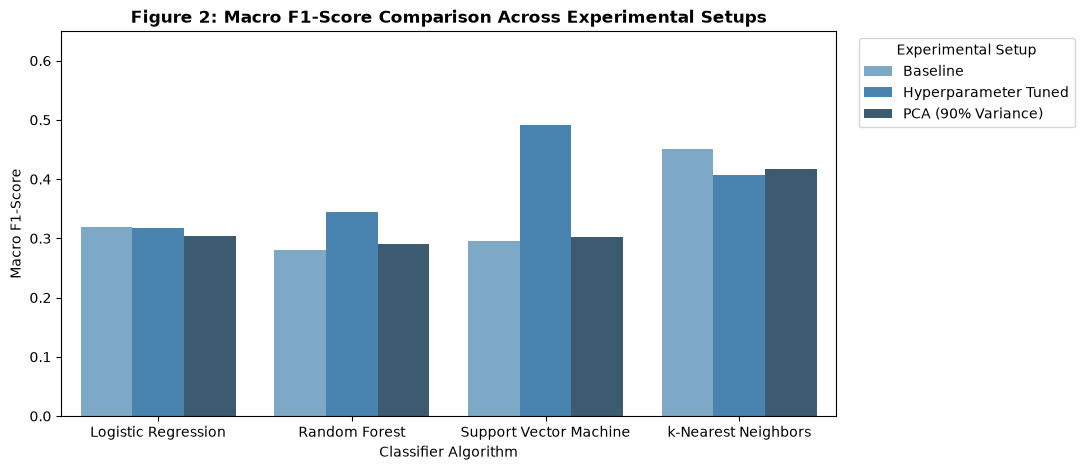

In [20]:
plt.figure(figsize=(10, 5))
bar_plot = sns.barplot(
    data=df_master,
    x="Algorithm",
    y="Macro F1-Score",
    hue="Experimental Setup",
    palette="Blues_d",
)
plt.title(
    "Figure 2: Macro F1-Score Comparison Across Experimental Setups",
    fontweight="bold",
)
plt.ylim(0, 0.65)
plt.ylabel("Macro F1-Score")
plt.xlabel("Classifier Algorithm")
plt.legend(title="Experimental Setup", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.annotate()
plt.tight_layout()
plt.savefig("experimental_comparison_f1.png", dpi=300)
plt.show()